In [31]:
# Code imports
from lib.opt_types import *
from lib.utils import *

# Image inpainting with proximal methods - 30 points + 2 bonus points

Image in-painting consists of reconstructing the missing parts of an image from a given incomplete image.

By exploiting some prior knowledge on the image, it is possible to in-paint images that have a large portion of their pixels missing. In this part of the homework, we are going to study different methods to achieve this goal.

We consider a subsampled image $\mathbf{b} = \mathbf{P}_{\Omega} \mathbf{x}$, where $\mathbf{P}_{\Omega} \in \mathbb{R}^{n \times p}$ is an operator that selects only few, $n \ll p := m^2$, pixels from the vectorized image $\mathbf{x} \in \mathbb{R}^p$. Our goal is to reconstruct the original image $\mathbf{x}$.

### Prior knowledge

Image inpainting is impossible without having some prior knowledge on the structure of the true image $\mathbf{x}$. 

We will explore and compare the following prior assumptions we can make on the true image: 
>  **Assumption**: There exists a orthonormal basis $\mathbf{W} \in \mathbb{R}^{p\times p}$ such that $\mathbf{x}$ can be sparsely represented in that basis, i.e, $\mathbf{W} \mathbf{x}$ is a vector with few non-zero coefficients. Writing $\boldsymbol\alpha=\mathbf W\mathbf x$, we have $\mathbf x=\mathbf W^\top\boldsymbol\alpha$. We promote sparsity by penalizing $\|\boldsymbol\alpha\|_1$, a convex surrogate for the number of nonzero coefficients. We assume that this basis is known and corresponds to the _wavelet basis_. Under this assumption, the reconstruction problem corresponds to solving the following optimization problem:
$$
\min_{\mathbf{\alpha} \in \mathbb{R}^{p}} \underbrace{ \frac{1}{2}\|\mathbf{b} - \mathbf{P}_{\Omega} \mathbf{W}^T\mathbf{\alpha} \|_2^2}_{f_{\ell_1}(\mathbf{\alpha})} + \underbrace{\lambda_{\ell_1} \|\mathbf{\alpha}\|_1}_{g_{\ell_1}(\mathbf{\alpha})},
$$
where $\lambda_{\ell_1}$ is a coefficient we will need to choose.



# PART 1: Optimizing with an $\ell_1$ norm regularization

The optimization problem we are looking to solve have an objective function of the form:
$$
	 f(\mathbf{x}) + g(\mathbf{x}).
$$

These types of objectives are referred to as _composite objectives_ where one term, $f$, is smooth and differentiable and the other term $g$ is non-differentiable.

---

## Code structure:

Recall that we have been working with the `Function` type so far. We will augment this type to represent functions that are not differentiable:

- Given a `Function` `g` you can obtain a subgradient at a point `x` by calling `g.subgrad(x)`.

Moreover, since we are dealing with _composite_ problems with a an objective function that can be written `f + g`, we define the `CompositeFunction` type defined as
```python
@dataclass
class CompositeFunction:
    f: Function
    g: Function
```

The iterative schemes you will implement will receive a composite function that they can unpack as follows:

```python
def state_update(composite_function, state):
    f, g = composite_function

```

#### Question 1: (5 point)

A first approach to solve a non-smooth optimization problem can be to turn to subgradients. Review slide 42-44 of Lecture 6, and implement `SubG` with $\alpha_k = \frac{0.1}{\sqrt{k}}$, starting the counter at $k=1$.

In [32]:
@dataclass
class SubG_state(OptState):
    x_k: Vector
    k: int
    pass


In [ ]:
def SubG_update(composite_function, state):
    f, g = composite_function
    alpha = 0.1 / np.sqrt(state.k)
    x_new = state.x_k -alpha*(f.grad(state.x_k) +g.subgrad(state.x_k))
    return SubG_state(x_k=x_new, k=state.k + 1)

def SubG_initialize(composite_function, x_zero):
    return SubG_state(x_k=x_zero, k=1)


In [34]:
SubG = OptAlgorithm(name="SubG", init_state=SubG_initialize, state_update=SubG_update)

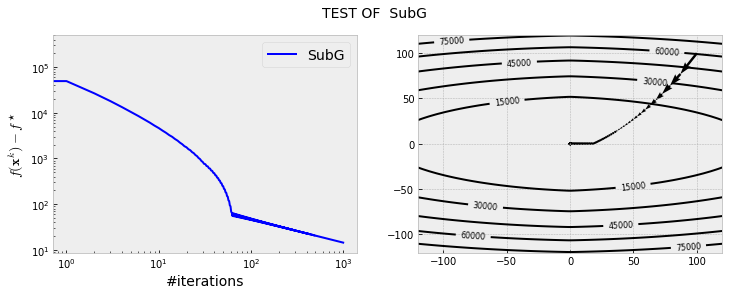

In [35]:
test_composite(SubG)


---

Another, more efficient approach, as we saw in Lecture 8, is to minimize such a function by using proximal gradient algorithms, provided that $g$ is _proximable_ (i.e., its proximal operator is efficient to evaluate). We recall the proximal operator of $g$ as the solution to the following convex problem:
$$
\mathrm{prox}_g(\mathbf{z}) := \mathrm{arg}\min_{\mathbf{y}\in\mathbb{R}^d}\{ g(\mathbf{y}) + \frac{1}{2}\Vert\mathbf{y} - \mathbf{z}\Vert_2^2\}.
$$

#### Question 2 (2 points)

Given $g_{\ell_1}: \mathbb{R}^p \rightarrow \mathbb{R}, \; g_{\ell_1}(\mathbf{x}) :=  \beta \|\mathbf{x}\|_1$ with $\beta\geq0$, show that its proximal function can be written as
    $$
    \mathrm{prox}_{\gamma g_{\ell_1}}(\mathbf{z}) = \max(|\mathbf{z}|-\beta \gamma,0) \circ \mathrm{sign}(\mathbf{z}), \; \text{for any }\mathbf{z} \in \mathbb{R}^p,\; \gamma \in \mathbb{R}_+
    $$
			where the operators $\max$, $\mathrm{sign}$ and $\lvert \cdot \lvert$ are applied coordinate-wise to the vector $\mathbf{z}$ and $\circ$ stands for $(\mathbf{x} \circ \mathbf{y})_i = x_i y_i$. Such a regularizer imposes sparsity on the solutions.


Answer :
$$
\operatorname{prox}_{\gamma g_{\ell_1}}(\mathbf{z})
=
\arg\min_{\mathbf{y}\in\mathbb{R}^{p}}
\left\{
\gamma\beta\|\mathbf{y}\|_1
+\frac{1}{2}\|\mathbf{y}-\mathbf{z}\|_2^2
\right\}.
$$

The objective separates across coordinates. For each coordinate \(i\), we minimize
$$
\phi_i(y_i)
=
\gamma\beta|y_i|+\frac{1}{2}(y_i-z_i)^2.
$$
This gives
$$
\bigl(\operatorname{prox}_{\gamma g_{\ell_1}}(\mathbf{z})\bigr)_i
=
\begin{cases}
z_i-\gamma\beta, & z_i>\gamma\beta,\\
0, & |z_i|\leq\gamma\beta,\\
z_i+\gamma\beta, & z_i<-\gamma\beta.
\end{cases}
$$
Therefore,
$$
\operatorname{prox}_{\gamma g_{\ell_1}}(\mathbf{z})
=
\max\bigl(|\mathbf{z}|-\gamma\beta,\,0\bigr)
\circ\operatorname{sign}(\mathbf{z}).
$$

#### Question 3 (1 point)
 Fill in the function `l1_prox` with the proximal operator of $g_{\ell_1}$.

In [36]:
def l1_prox(gamma, z, beta):
    return np.maximum(np.abs(z) - gamma * beta, 0) * np.sign(z)


#### Question 4 (4 points)

From here on, in order to speed-up the convergence of the optimization, let's assume that the function $f$ has been made to be $\mu$-strongly convex by the addition of an $\ell_2$ regularization term to the function $f$, while the $\ell_1$ term, $g$, has remained unchanged. As such, we must now utilize the strong-convexity versions of the composite optimization algorithms.

Using the information in Lecture 7 slide 21 fill in the codes of the method $\text{ISTA}_\mu$. In the provided quadratic test, $\beta=30$. Use `g.prox(alpha, z)` to apply the proximal operator of the supplied regularizer, including its weight.

In [37]:
@dataclass
class ISTA_state(OptState):
    x_k: Vector


In [38]:
def ISTA_update(composite_function, state):
    f, g = composite_function
    alpha = 1.0 / f.lips_grad
    z = state.x_k - alpha * f.grad(state.x_k)
    x_new = g.prox(alpha, z)
    return ISTA_state(x_k=x_new)

def ISTA_initialize(composite_function, x_zero):
    return ISTA_state(x_k=x_zero)


In [39]:
ISTA = OptAlgorithm(name="ISTA", init_state= ISTA_initialize, state_update=ISTA_update)

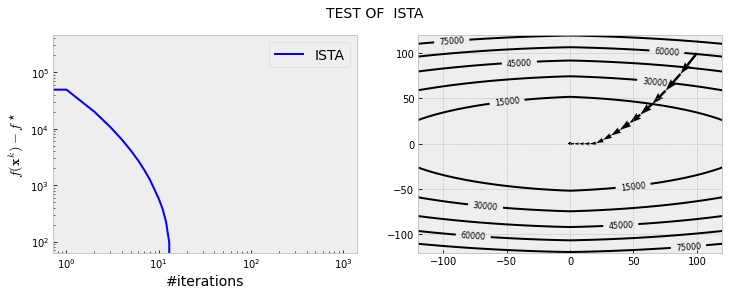

In [40]:
test_composite(ISTA, prox=l1_prox)


#### Question 5  (7 points)

Using the information in Lecture 7 slide 21 fill in the codes of the method $\text{FISTA}_\mu$.

In [41]:
@dataclass 
class FISTA_state(OptState):
    x_k: Vector
    y_k: Vector


In [42]:
import numpy

def FISTA_update(composite_function, state):
    f, g = composite_function

    L = f.lips_grad
    mu = f.strng_cvx
    alpha = 1.0 / L
    momentum = (numpy.sqrt(L) - numpy.sqrt(mu)) / (
        numpy.sqrt(L) + numpy.sqrt(mu)
    )

    z = state.y_k - alpha * f.grad(state.y_k)
    x_new = g.prox(alpha, z)
    y_new = x_new + momentum * (x_new - state.x_k)

    return FISTA_state(x_k=x_new, y_k=y_new)

def FISTA_initialize(composite_function, x_zero):
    return FISTA_state(x_k=x_zero, y_k=x_zero)


In [43]:
FISTA = OptAlgorithm(name="FISTA", init_state= FISTA_initialize, state_update=FISTA_update)

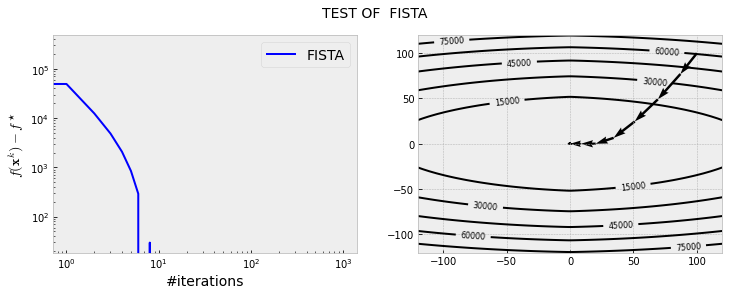

In [44]:
test_composite(FISTA, prox=l1_prox)


#### Question 6  (2 points)

Compare the convergence rates of the three methods and analyze whether the observed results align with their theoretical bounds.

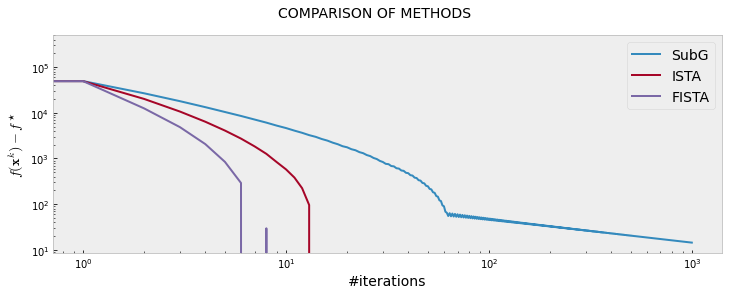

In [45]:
list_of_methods = [SubG, ISTA, FISTA]
compare_composite(list_of_methods, prox=l1_prox)


FISTA is the fastest method, followed by ISTA and then by the sub gradient method. 
Overall this is consistent with the theory :
FISTA and ISTA have linear rate
while the sub gradient method converges sublinearly.


# Part 2: Application


We have now implemented multiple methods that can solve composite optimization problems. We will now apply them to an image inpainting problem.


Take a natural image, or better a picture of you, and place it in the same directory as this notebook.

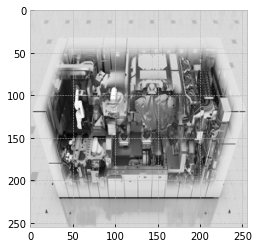

In [69]:
from lib.inpainting import *

image = load("lib/asml.jpg")  # FILL: replace with your image filename.

With this image in hand, let us subsample it and try to reconstruct the original.

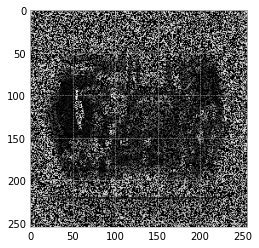

In [70]:
subsampled = show_subsampled(image)

For the rest of the questions, to ensure the function is 
$\mu$-strongly convex, we need to add an $\ell_2$ regularization term to it. As a result, we change the definition of $f_{\ell_1}(\mathbf{\alpha})$ as follows:
$$
    f_{\ell_1}(\mathbf{\alpha}) = \frac{1}{2}\|\mathbf{b} - \mathbf{P}_{\Omega} \mathbf{W}^T\mathbf{\alpha} \|_2^2 + \frac{1}{2}\mu \|\mathbf{\alpha}\|_2^2 
    $$

and the composite function becomes:
 $$
    \min_{\mathbf{\alpha} \in \mathbb{R}^{p}} \underbrace{ \frac{1}{2}\|\mathbf{b} - \mathbf{P}_{\Omega} \mathbf{W}^T\mathbf{\alpha} \|_2^2 + \frac{1}{2}\mu \|\mathbf{\alpha}\|_2^2 }_{f_{\ell_1}(\mathbf{\alpha})} + \underbrace{\lambda_{\ell_1} \|\mathbf{\alpha}\|_1}_{g_{\ell_1}(\mathbf{\alpha})},
    $$

By adding this regularization, we ensure better properties for optimization, making the solution more stable and well-behaved.

In the following cells we will define the optimization problems we need to solve to perform the reconstruction.

- We provide you with a function `P` that acts like the matrix $\mathbf{P}_{\Omega}$. That is, given a vector `x`, it returns a subsampled vector `P(x)` that corresponds to $\mathbf{P}_{\Omega} \mathbf{x}$. We also give you `P_T` which acts like $\mathbf{P}^\top$.
- We provide you with a function `W` and `W_T` that act like the matrix $\mathbf{W}$ and $\mathbf{W^\top}$ respectively. That is, for a vector `x`, `W(x)` and `W_T(x)` return $\mathbf{W}\mathbf{x}$ and $\mathbf{W^\top}\mathbf{x}$ respectively.

__(a)__ (1 point) Using these provided functions, define the observed variable `b` in the cell below.

In [71]:
from lib.inpainting import P, P_T, W, W_T

x = image.reshape(-1) #flattened image

b = P(x) #subsampled image

__(b)__ (1 point) Now define the function `f_l1` as described earlier in the problem text.

In [ ]:
mu = 1e-4 # Desired strong convexity of f
def f_l1(alpha):
    res = b- P(W_T(alpha))
    return 0.5* np.linalg.norm(res)**2 +0.5*mu * np.linalg.norm(alpha)**2


__(c)__ (1 point) Write the gradient of $f_{\ell_1}(\mathbf{\alpha})$.

In [73]:
def grad_f_l1(alpha):
    residual = P(W_T(alpha)) - b
    return W(P_T(residual)) + mu * alpha


__(d)__ (1 points) Find the Lipschitz constant of $\nabla_\mathbf{\alpha} f_{\ell_1}(\mathbf{\alpha})$ analytically and fill it in the cell below. 

Let $A = P W^T$. Then
$$
f_{\ell_1}(\alpha)
=
\frac{1}{2}\|b-A\alpha\|_2^2
+
\frac{\mu}{2}\|\alpha\|_2^2,
$$
and
$$
\nabla f_{\ell_1}(\alpha)
=
A^\top(A\alpha-b)+\mu\alpha.
$$

Since $P$ selects coordinates, $\|P\|_2 \leq 1$. The wavelet transform $W_T$ is orthonormal, so $\|W_T\|_2 = 1$. Hence $\|A\|_2 \leq 1$, and
$$
\begin{aligned}
\|\nabla f_{\ell_1}(\alpha)-\nabla f_{\ell_1}(\tilde{\alpha})\|_2
&=
\|(A^\top A+\mu I)(\alpha-\tilde{\alpha})\|_2\\
&\leq (\|A\|_2^2+\mu)\|\alpha-\tilde{\alpha}\|_2\\
&\leq (1+\mu)\|\alpha-\tilde{\alpha}\|_2.
\end{aligned}
$$
Therefore, a valid Lipschitz constant is
$$
L=1+\mu.
$$

In [74]:
lips_grad_f_l1 = 1.0 + mu


We have all the necessary ingredients to define the smooth part of our composite objective:

In [75]:
f_l1 = Function(f = f_l1, grad=grad_f_l1, lips_grad = lips_grad_f_l1, strng_cvx=mu)

For the non-smooth term, `l1` represents the unweighted $\ell_1$ norm. `Regularizer` applies the weight `lmda` to both the function value and its proximal operator, reusing `l1_prox` with $\beta=1$:

In [76]:
l1 = Function(f = lambda x: np.sum(np.abs(x), axis=0), prox=lambda gamma, z: l1_prox(gamma, z, beta=1))

g_l1 = Regularizer(l1)

In [77]:
composite_objective = CompositeFunction(f=f_l1, g=g_l1)

With the objective defined, we provide you with a function with the following signature:
```python
solve_composite(method: OptAlgorithm, composite_objective: CompositeFunction, lmda: float, max_iterations: int) -> Vector
```

In other words, the function takes an optimization algorithm `method`, a CompositeFunction `composite_objective`, a regularization parameter `lmda` and a number of iterations `max_iterations` and returns a vector which is the last iterate given by the `method`.



In [78]:
from lib.inpainting import solve_composite

__(e)__ (5 points) Using `solve_composite` reconstruct the subsampled image. Recall that the composite problem solves for $\mathbf{\alpha}$ so you need to convert the output back to an image and visualize it.

Select a reasonable value for `lmda`.

**Bonus (2 points).** Using `solve_composite` and the `PSNR` metric, find the best value for `lmda`.

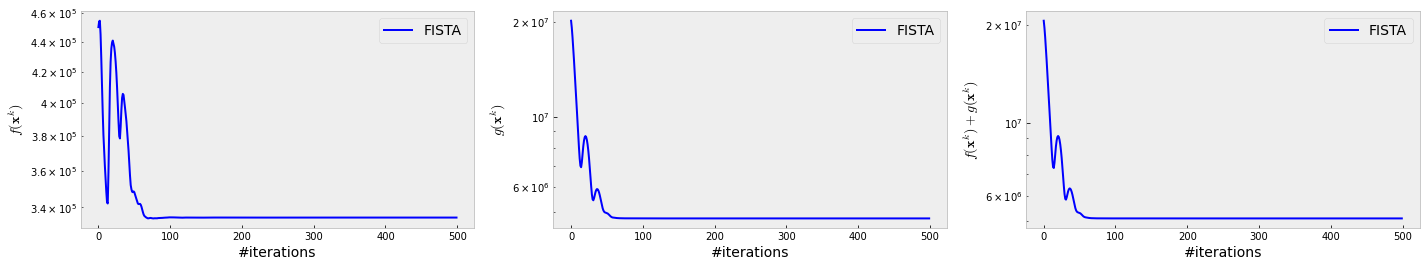

In [86]:
lmda = 4.67
out = solve_composite(FISTA, composite_objective, lmda=lmda, max_iterations=500)
flat_image_out = W_T(out)
image_out = flat_image_out.reshape(image.shape)


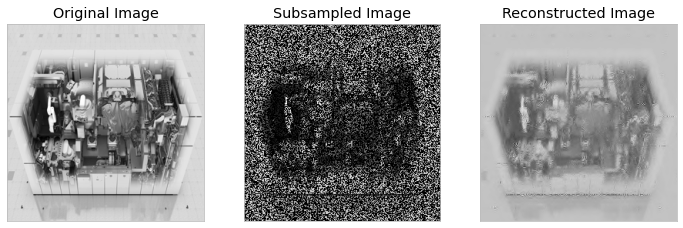

In [87]:
show(true = image, subsampled=subsampled, estimated=image_out)

The best lambda value seems to be 4,64. 

In [ ]:
lambdas = np.logspace(-1, 2, 10)
scores = []

for lam in lambdas:
    alpha = solve_composite(FISTA, composite_objective, lam, 500)
    rec = np.clip(W_T(alpha).reshape(image.shape), 0, 255)
    scores.append(10 * np.log10(255**2 / np.mean((image - rec)**2))) #PSNR justification part
    plt.close()

print("Best lambda:", lambdas[np.argmax(scores)])
print(list(zip(lambdas, scores)))


Best lambda: 4.6415888336127775
[(0.1, 21.49089712997826), (0.21544346900318834, 22.138062501007333), (0.46415888336127786, 22.38170448951381), (1.0, 22.489236232227476), (2.1544346900318834, 22.572818113832245), (4.6415888336127775, 22.62564970278362), (10.0, 22.518355344047677), (21.54434690031882, 21.93874049035761), (46.41588833612777, 20.465384478460816), (100.0, 18.216560453007023)]
